In [8]:
import matplotlib
import matplotlib.pylab as pylab
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import scipy.stats as stats
import os

# Exploratory Data Analysis

### Setup

In [10]:
pwd = %pwd

filename_gateways = os.path.join(pwd, "..", "dataset", "gateways.csv")
filename_readings = os.path.join(pwd, "..", "dataset", "readings.csv")
filename_units = os.path.join(pwd, "..", "dataset", "units.csv")

!Powershell.exe -Command "Get-Content {pwd}\..\dataset\gateways.csv -Head 5"
gateways_df = pd.read_csv(filename_gateways, sep=';')

!Powershell.exe -Command "Get-Content {pwd}\..\dataset\readings.csv -Head 5"
readings_df = pd.read_csv(filename_readings, sep='\t')

!Powershell.exe -Command "Get-Content {pwd}\..\dataset\units.csv -Head 5"
units_df = pd.read_csv(filename_units, sep=',', quotechar='"')

firmware_version;idDepot;gatewayId;date_install;vendor;Ipv4;dbmSignal;lon;idUnit;Technician
v2.7.0;46;GW-00000;2023/02/11;Miller-Parker;15.167.175.137;-72.40000;-7.17795;1470;FA­bio Pinto
v2.7.0;94;GW-00001;24 Nov 2018;Kent-Webb;60.190.76.185;-59.30000;-6.72380;1406;Rodrigo Pacheco
v2.7.0;61;GW-00002;2018/08/20;Schleich;23.152.231.98;-68.70000;-9.23071;1022;Camila Coelho
v3.4.1;27;GW-00003;2022-08-01;Faria;188.19.209.173;-79.90000;-7.92698;178;Carina Hering
idUnit	ts_cycle	motorCurrent	dpFilter	oilTemperature	pressureReservoir	pressureOil	rms_vibration	flowmeter	humidityIntake	current_aux	failure
U01837	07 Jan 2023	6.52327	16.51122	36.82184	8.76768	3.84876	5.82861	23.79687	41.18050	3.14415	0
U01444	2023/10/21	3.35043	31.18794	57.39092	9.41911	4.88801	6.68213	29.59370	11.72450	3.00981	0
U01073	07/17/2023, 05:03:00	3.86973	26.14267	61.13997	7.82343	3.06123	2.90913	24.92436	62.33287	0.84162	0
U01469	2023-09-02	3.64275	22.77432	61.45080	8.66640	3.97944	3.14111	29.75494	22.25817	4.11380	0
i

## Gateways

# INSERT RENAME COLUMN HERE

In [59]:
display(gateways_df.head())

,firmware_version,idDepot,gatewayId,date_install,vendor,Ipv4,dbmSignal,lon,idUnit,Technician
0,v2.7.0,46,GW-00000,2023/02/11,Miller-Parker,15.167.175.137,-72.4,-7.17795,1470.0,Fábio Pinto
1,v2.7.0,94,GW-00001,24 Nov 2018,Kent-Webb,60.190.76.185,-59.3,-6.72380,1406.0,Rodrigo Pacheco
2,v2.7.0,61,GW-00002,2018/08/20,Schleich,23.152.231.98,-68.7,-9.23071,1022.0,Camila Coelho
3,v3.4.1,27,GW-00003,2022-08-01,Faria,188.19.209.173,-79.9,-7.92698,178.0,Carina Hering
4,v2.7.0,54,GW-00004,21 Sep 2016,Seifert Seifert GbR,119.17.6.184,-72.1,-7.84725,1062.0,Chad Salazar


In [64]:
gateways_df.shape

(16000, 10)

In [65]:
print(gateways_df.head(10))

  firmware_version  idDepot gatewayId date_install               vendor  \
0           v2.7.0       46  GW-00000   2023/02/11        Miller-Parker   
1           v2.7.0       94  GW-00001  24 Nov 2018            Kent-Webb   
2           v2.7.0       61  GW-00002   2018/08/20             Schleich   
3           v3.4.1       27  GW-00003   2022-08-01                Faria   
4           v2.7.0       54  GW-00004  21 Sep 2016  Seifert Seifert GbR   
5           v1.2.5       17  GW-00005   2024-05-30            Neto S.A.   
6           v1.2.5      114  GW-00006   2024/01/24              Marques   
7           v1.2.5       67  GW-00007   2015/05/01                Gunpf   
8           v3.4.1       15  GW-00008  13 Dec 2021            Kent-Webb   
9           v3.4.1      103  GW-00009   2022-02-25          Flowers LLC   

             Ipv4  dbmSignal      lon  idUnit                  Technician  
0  15.167.175.137      -72.4 -7.17795  1470.0                 Fábio Pinto  
1   60.190.76.185     

In [66]:
gateways_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   firmware_version  16000 non-null  str    
 1   idDepot           16000 non-null  int64  
 2   gatewayId         16000 non-null  str    
 3   date_install      16000 non-null  str    
 4   vendor            16000 non-null  str    
 5   Ipv4              16000 non-null  str    
 6   dbmSignal         16000 non-null  float64
 7   lon               16000 non-null  float64
 8   idUnit            2000 non-null   float64
 9   Technician        16000 non-null  str    
dtypes: float64(3), int64(1), str(6)
memory usage: 2.2 MB


In [67]:
gateways_df.describe()

,idDepot,dbmSignal,lon,idUnit
count,16000.000000,16000.000000,16000.000000,2000.000000
mean,59.320062,-69.845756,-7.749522,1000.500000
std,34.328884,9.979199,0.890287,577.494589
min,0.000000,-110.000000,-9.299800,1.000000
25%,30.000000,-76.600000,-8.515750,500.750000
50%,59.000000,-69.900000,-7.754480,1000.500000
75%,89.000000,-63.000000,-6.976895,1500.250000
max,119.000000,-40.000000,-6.200200,2000.000000


In [24]:
gateways_df.Technician.unique()

<ArrowStringArray>
[               'Fábio Pinto',            'Rodrigo Pacheco',
              'Camila Coelho',              'Carina Hering',
               'Chad Salazar',         'Herr Dittmar Römer',
 'Joana Henriques-Figueiredo',              'Angela Watson',
          'Christopher Mayer',               'Rita Harloff',
 ...
              'Kelly Lindsey',             'Denis Pinheiro',
                 'Veit Dietz',               'James Waller',
          'Prof. Ariane Karz',                'David Davis',
              'Inês Monteiro',           'Yvonne Gutierrez',
            'Hüseyin Radisch',                   'Ana Melo']
Length: 120, dtype: str

In [29]:
gateways_df.groupby('Technician').size()

Technician
Abbas Trubin               115
Adelheid Pechel            135
Afonso Nascimento-Alves    128
Ahmed Bachmann             126
Allison Rodriguez          146
                          ... 
Veit Dietz                 147
Vitória Oliveira-Faria     137
Vítor Valente              124
Yvonne Gutierrez           140
Álvaro Neves               132
Length: 120, dtype: int64

In [30]:
gateways_df['dbmSignal'].mean()

np.float64(-69.84575625000001)

In [31]:
gateways_df['dbmSignal'].median()

np.float64(-69.9)

In [32]:
stats.mode(gateways_df['dbmSignal'])

ModeResult(mode=np.float64(-71.3), count=np.int64(80))

In [33]:
np.var(gateways_df['dbmSignal'])

np.float64(99.57819449058594)

In [34]:
np.std(gateways_df['dbmSignal'])

np.float64(9.978887437514562)

array([[<Axes: title={'center': 'idDepot'}>,
        <Axes: title={'center': 'dbmSignal'}>],
       [<Axes: title={'center': 'lon'}>,
        <Axes: title={'center': 'idUnit'}>]], dtype=object)

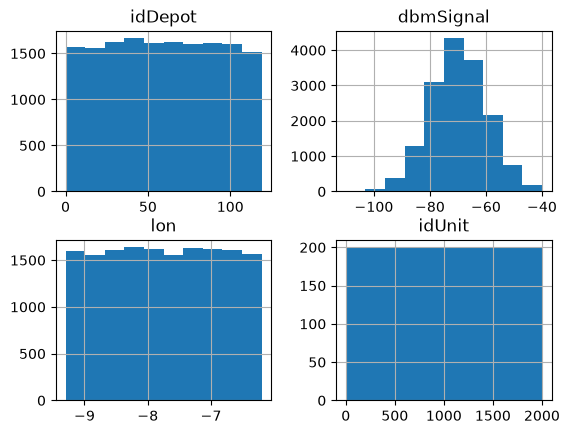

In [35]:
gateways_df.hist()

In [36]:
sns.boxplot(data=gateways_df, x="1", y="2")

ValueError: Could not interpret value `1` for `x`. An entry with this name does not appear in `data`.

## Readings

# INSERT RENAME COLUMN HERE

In [60]:
display(readings_df.head())

,idUnit,ts_cycle,motorCurrent,dpFilter,oilTemperature,pressureReservoir,pressureOil,rms_vibration,flowmeter,humidityIntake,current_aux,failure
0,U01837,07 Jan 2023,6.52327,16.51122,36.82184,8.76768,3.84876,5.82861,23.79687,41.18050,3.14415,0
1,U01444,2023/10/21,3.35043,31.18794,57.39092,9.41911,4.88801,6.68213,29.59370,11.72450,3.00981,0
2,U01073,"07/17/2023, 05:03:00",3.86973,26.14267,61.13997,7.82343,3.06123,2.90913,24.92436,62.33287,0.84162,0
3,U01469,2023-09-02,3.64275,22.77432,61.45080,8.66640,3.97944,3.14111,29.75494,22.25817,4.11380,0
4,U00271,2023/07/11,5.77419,31.62403,46.30993,9.42113,4.18919,NaN,30.53777,86.07477,3.03859,1


In [63]:
readings_df.shape

(15810, 12)

## Units

# INSERT RENAME COLUMN HERE

In [61]:
display(units_df.head())

,idDepot,last_overhaul,classDuty,serial_number,Manufacturer,hoursService,idUnit
0,69,2016/04/20,H,FN-1865-92664,Correia,19153.0,1
1,85,2022/09/30,H,VE-5385-79331,Murray PLC,14182.1,2
2,56,2023-08-07,N,RK-8589-24716,Pacheco,10193.1,3
3,93,2020-06-20,heavy,SK-1876-42353,Nascimento,12223.0,4
4,76,"12/15/2023, 00:00:00",N,NK-8717-68406,"Camacho, Lowe and Robinson",3974.3,5
